# Grafo de colaboración de Daniel Radcliffe

**Katherine Diéguez** — Parte individual del proyecto final *Todo modelo es un voto ponderado*
Análisis y Ciencia de Datos, Facultad de Ingeniería, Universidad del Istmo

Construcción del grafo de colaboración de Daniel Radcliffe con datos de TMDB (1975–2025, elenco principal con `order < 5`), visualización y análisis espectral.

## Configuración

Librerías y lectura de la API key. La key se lee de `tmdb_api_key.txt`, que no está en el repositorio. Si no existe, el notebook trabaja solo con el cache.

In [1]:
import os, json, time, re
from collections import defaultdict
from itertools import combinations

import numpy as np
import requests


def cargar_api_key(ruta="tmdb_api_key.txt"):
    """Lee la key de un archivo local (ignorado por git) o de una variable de entorno.
    Si no hay ninguna, devuelve None y el notebook trabaja solo con el cache."""
    if os.path.exists(ruta):
        with open(ruta) as f:
            return f.read().strip()
    return os.environ.get("TMDB_API_KEY")

## I.2 Clase `Graph`

Grafo no dirigido y con pesos. Cada arista se guarda con la clave `(min(a, b), max(a, b))`, así que $(a, b)$ y $(b, a)$ son la misma arista.

In [2]:
class Graph:
    """Grafo no dirigido y con pesos.
    Nodos: tuplas (id, name). Aristas: {(a, b): peso} guardadas siempre con a < b,
    así (a, b) y (b, a) son la misma clave."""

    def __init__(self):
        self.nodes = []      # [(id, name), ...] en orden de inserción
        self._names = {}     # id -> name
        self.edges = {}      # {(min, max): peso}

    @staticmethod
    def _clave(a, b):
        return (a, b) if a < b else (b, a)

    def add_node(self, id, name):
        if id not in self._names:
            self.nodes.append((id, name))
            self._names[id] = name

    def add_edge(self, a, b):
        if a == b:
            return  # sin lazos: un actor no colabora consigo mismo
        if a not in self._names or b not in self._names:
            raise KeyError(f"Arista ({a}, {b}) con un nodo que no existe")
        k = self._clave(a, b)
        self.edges[k] = self.edges.get(k, 0) + 1

    def name(self, id):
        return self._names[id]

    def total_nodes(self):
        return len(self.nodes)

    def total_edges(self):
        return len(self.edges)

    def degrees(self):
        """Grado = número de aristas que tocan al nodo (sin pesos)."""
        grado = {id: 0 for id, _ in self.nodes}
        for a, b in self.edges:
            grado[a] += 1
            grado[b] += 1
        return grado

    def max_degree_nodes(self):
        """{id: grado} con el nodo de grado máximo, o todos los empatados."""
        grado = self.degrees()
        if not grado:
            return {}
        m = max(grado.values())
        return {id: g for id, g in grado.items() if g == m}

    def adjacency(self):
        """Matriz de adyacencia con pesos y la lista de ids en el orden de sus filas."""
        ids = [id for id, _ in self.nodes]
        pos = {id: i for i, id in enumerate(ids)}
        A = np.zeros((len(ids), len(ids)))
        for (a, b), w in self.edges.items():
            A[pos[a], pos[b]] = w
            A[pos[b], pos[a]] = w
        return A, ids

## I.3 Clase `TMDBAPIUtils`

La clase TMDBAPIUtils permite consultar la información de películas y actores mediante la API de TMDB. Sus métodos recuperan los elencos de las películas y la filmografía de los actores, aplicando filtros por fechas y orden de aparición. Además, utiliza archivos JSON como caché para evitar consultas repetidas y permite aplicar los filtros sobre los datos almacenados. Se excluyen los documentales y las participaciones en las que los actores aparecen interpretándose a sí mismos.

In [3]:
# "Himself", "Herself", "Self", "Himself (voice)", "Self - Host"... pero no "Selfish"
_PATRON_SI_MISMO = re.compile(r"\b(?:him|her|them)?self\b", re.IGNORECASE)

def es_si_mismo(personaje):
    return bool(personaje) and bool(_PATRON_SI_MISMO.search(personaje))


class TMDBAPIUtils:
    BASE = "https://api.themoviedb.org/3"

    def __init__(self, api_key=None, cache_dir="cache"):
        self.api_key = api_key
        self.cache_dir = cache_dir
        os.makedirs(cache_dir, exist_ok=True)

    def _get(self, endpoint, archivo):
        """Devuelve la respuesta cruda del API. Primero busca en el cache;
        si no está, consulta el API y la guarda."""
        ruta = os.path.join(self.cache_dir, archivo)
        if os.path.exists(ruta):
            with open(ruta, encoding="utf-8") as f:
                return json.load(f)
        if not self.api_key:
            raise RuntimeError(f"No hay cache para {archivo} ni API key.")
        for intento in range(5):
            r = requests.get(f"{self.BASE}{endpoint}",
                             params={"api_key": self.api_key, "language": "en-US"},
                             timeout=20)
            if r.status_code == 429:          # demasiadas solicitudes: esperar y reintentar
                time.sleep(2 ** intento)
                continue
            r.raise_for_status()
            datos = r.json()
            with open(ruta, "w", encoding="utf-8") as f:
                json.dump(datos, f, ensure_ascii=False, indent=1)
            return datos
        raise RuntimeError(f"El API siguió rechazando {endpoint}")

    def get_movie_cast(self, movie_id, limit=None, exclude_ids=None):
        datos = self._get(f"/movie/{movie_id}/credits", f"movie_{movie_id}_credits.json")
        excluir = set(exclude_ids or [])
        elenco = []
        for m in datos.get("cast", []):
            if limit is not None and not (0 <= m["order"] <= limit - 1):
                continue
            if m["id"] in excluir:
                continue
            elenco.append({"id": m["id"], "name": m["name"],
                           "character": m.get("character", ""), "order": m["order"]})
        return sorted(elenco, key=lambda m: m["order"])

    def get_movie_credits_for_person(self, person_id, start_date=None, end_date=None):
        datos = self._get(f"/person/{person_id}/movie_credits",
                          f"person_{person_id}_movie_credits.json")
        por_peli = {}
        for c in datos.get("cast", []):
            fecha = c.get("release_date") or ""
            if not fecha:                                  # sin fecha no se puede ubicar en la ventana
                continue
            if start_date and fecha < start_date:          # YYYY-MM-DD se compara bien como texto
                continue
            if end_date and fecha > end_date:
                continue
            if 99 in (c.get("genre_ids") or []):           # documental
                continue
            if es_si_mismo(c.get("character")):
                continue
            credito = {"id": c["id"], "title": c.get("title", ""),
                       "release_date": fecha, "order": c.get("order")}
            # si la persona aparece dos veces en la misma película, se queda el mejor order
            previo = por_peli.get(c["id"])
            if previo is None or (credito["order"] is not None and
                                  (previo["order"] is None or credito["order"] < previo["order"])):
                por_peli[c["id"]] = credito
        return list(por_peli.values())

## I.4 Construcción del grafo

Ventana: 1 de enero de 1975 a 31 de diciembre de 2025, `limit = 5`. Una película cuenta para un actor si salió dentro de la ventana y el actor aparece con `order < 5`.

In [4]:
SEMILLA_ID = 10980            # Daniel Radcliffe en TMDB (themoviedb.org/person/10980)
INICIO, FIN, LIMITE = "1975-01-01", "2025-12-31", 5

api = TMDBAPIUtils(api_key=cargar_api_key(), cache_dir="cache")
g = Graph()

def cuenta(credito):
    """Una película cuenta para un actor si está en la ventana (ya filtrada) y order < 5."""
    return credito["order"] is not None and credito["order"] < LIMITE

# (a) la semilla
g.add_node(SEMILLA_ID, "Daniel Radcliffe")

# (b) los coprotagonistas de cada película que cuenta para la semilla
pelis_semilla = [c for c in api.get_movie_credits_for_person(SEMILLA_ID, INICIO, FIN) if cuenta(c)]
for p in pelis_semilla:
    for m in api.get_movie_cast(p["id"], limit=LIMITE, exclude_ids=[SEMILLA_ID]):
        g.add_node(m["id"], m["name"])

# (c) aristas: una por película y por pareja, sin agregar nodos nuevos
pelis_por_actor = {}                     # id actor -> {id película: crédito}
for id_actor, _ in g.nodes:
    creditos = api.get_movie_credits_for_person(id_actor, INICIO, FIN)
    pelis_por_actor[id_actor] = {c["id"]: c for c in creditos if cuenta(c)}

actores_por_peli = defaultdict(set)      # id película -> actores del grafo para los que cuenta
for id_actor, pelis in pelis_por_actor.items():
    for id_peli in pelis:
        actores_por_peli[id_peli].add(id_actor)

for id_peli, actores in actores_por_peli.items():
    for a, b in combinations(sorted(actores), 2):
        g.add_edge(a, b)

print("Películas que cuentan para la semilla:", len(pelis_semilla))
print("Nodos:", g.total_nodes(), "| Aristas:", g.total_edges())
for id, grado in g.max_degree_nodes().items():
    print(f"Mayor grado: {g.name(id)} (id {id}) con {grado} aristas")

Películas que cuentan para la semilla: 30
Nodos: 101 | Aristas: 373
Mayor grado: Daniel Radcliffe (id 10980) con 100 aristas


**Resultados.** Se identificaron 30 películas válidas para Daniel Radcliffe dentro del período establecido. A partir de ellas se construyó un grafo de 101 nodos y 373 aristas, donde los nodos representan actores y las aristas representan colaboraciones cinematográficas.

Daniel Radcliffe presentó el mayor grado, con 100 conexiones, debido a que es el actor semilla y está conectado directamente con todos los demás actores incorporados al grafo. Entre sus colaboradores más frecuentes destacan Rupert Grint y Emma Watson, con 8 películas compartidas cada uno, seguidos por Michael Gambon, con 3 películas.

### Matriz de adyacencia

Revisión rápida de $A$ y de los coprotagonistas con más películas compartidas con la semilla.

In [5]:
A, ids = g.adjacency()
pos = {id: i for i, id in enumerate(ids)}
nombres = [g.name(id) for id in ids]
grado = g.degrees()                      # grado sin pesos, como lo define la clase Graph
i_semilla = pos[SEMILLA_ID]

print("A simétrica:", np.allclose(A, A.T), "| diagonal en cero:", np.all(np.diag(A) == 0))
print("Suma de pesos / 2 =", A.sum() / 2, "(películas compartidas, sumadas sobre todas las parejas)")
print("\nCoprotagonistas con más películas compartidas con la semilla:")
for j in np.argsort(-A[i_semilla])[:8]:
    print(f"  {nombres[j]:<30} {int(A[i_semilla, j])} películas")

A simétrica: True | diagonal en cero: True
Suma de pesos / 2 = 446.0 (películas compartidas, sumadas sobre todas las parejas)

Coprotagonistas con más películas compartidas con la semilla:
  Rupert Grint                   8 películas
  Emma Watson                    8 películas
  Michael Gambon                 3 películas
  Toby Jones                     2 películas
  Helena Bonham Carter           2 películas
  David Haig                     2 películas
  Woody Harrelson                2 películas
  Richard Harris                 1 películas


## I.5 Visualización

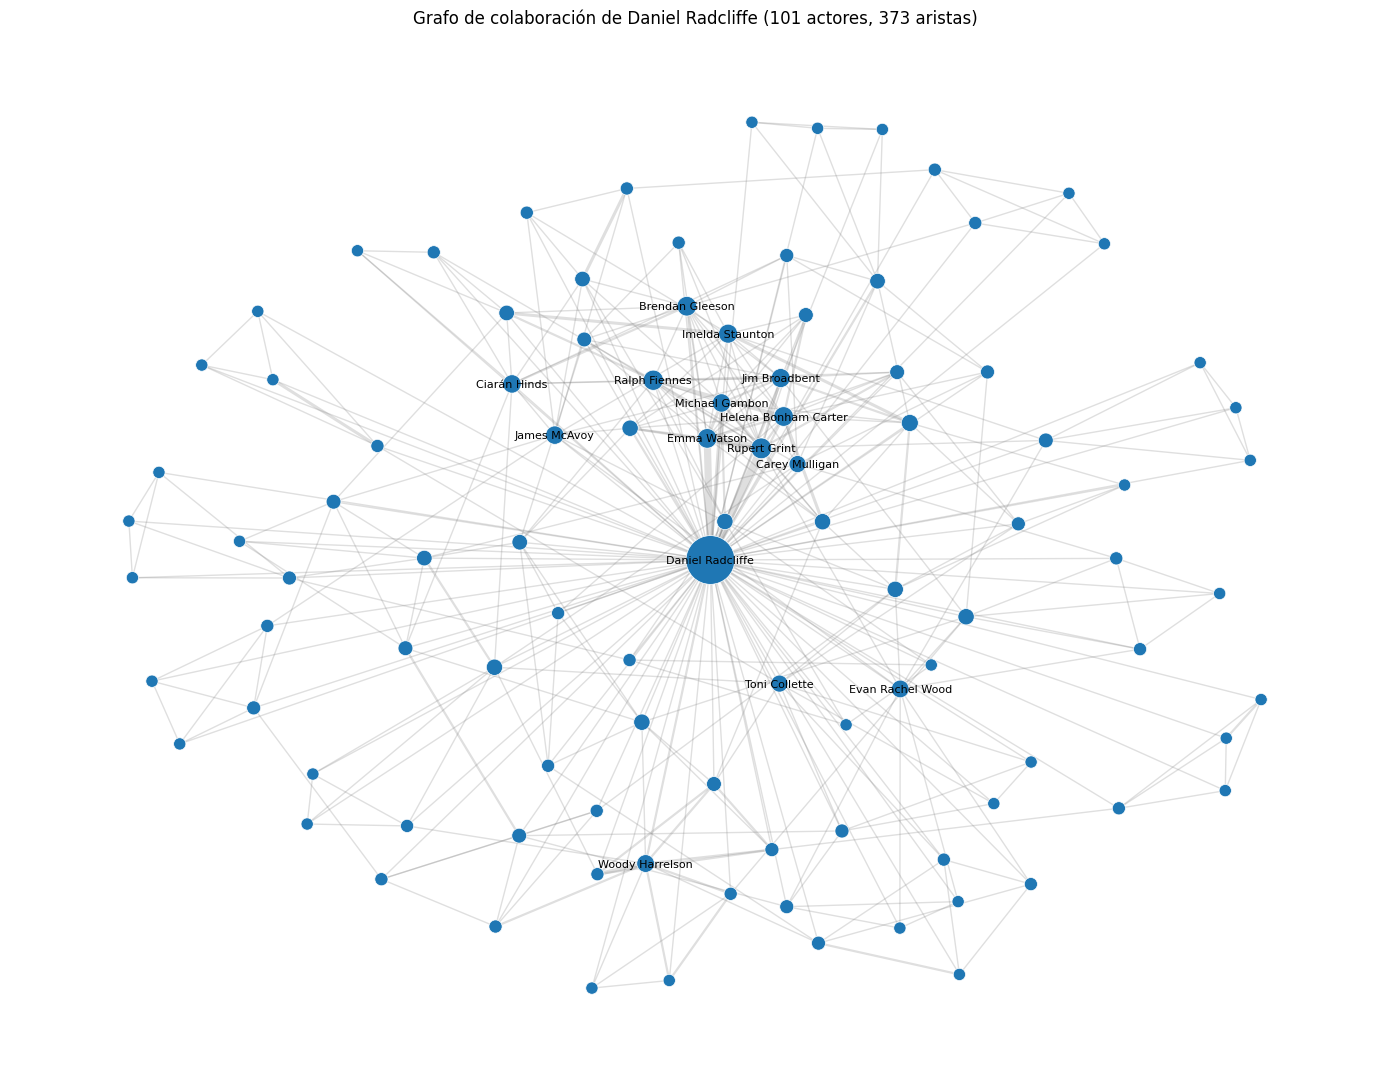

In [6]:
import matplotlib.pyplot as plt
import networkx as nx  

os.makedirs("figuras", exist_ok=True)

def dibujar_grafo(A, nombres, colores=None, titulo="", archivo=None, n_etiquetas=15, semilla=0):
    G = nx.from_numpy_array(A)
    posiciones = nx.spring_layout(G, weight="weight", seed=semilla, k=0.35, iterations=200)
    grados = (A > 0).sum(axis=1)
    pesos = np.array([G[u][v]["weight"] for u, v in G.edges()])

    fig, ax = plt.subplots(figsize=(14, 11))
    nx.draw_networkx_edges(G, posiciones, ax=ax, width=0.4 + 0.6 * pesos, alpha=0.25, edge_color="gray")
    nx.draw_networkx_nodes(G, posiciones, ax=ax, node_size=30 + 12 * grados,
                           node_color=colores if colores is not None else "tab:blue",
                           cmap=plt.cm.tab10 if colores is not None else None,
                           edgecolors="white", linewidths=0.5)
    top = np.argsort(-grados)[:n_etiquetas]          # solo se etiquetan los de mayor grado
    nx.draw_networkx_labels(G, posiciones, labels={i: nombres[i] for i in top}, font_size=8, ax=ax)
    ax.set_title(titulo)
    ax.axis("off")
    plt.tight_layout()
    if archivo:
        plt.savefig(archivo, dpi=200, bbox_inches="tight")
    plt.show()

dibujar_grafo(A, nombres,
              titulo=f"Grafo de colaboración de Daniel Radcliffe ({g.total_nodes()} actores, {g.total_edges()} aristas)",
              archivo="figuras/grafo_radcliffe.png")

La visualización permite identificar a Daniel Radcliffe como el nodo central de la red, conectado con los distintos grupos de actores. El tamaño de los nodos representa su grado y el grosor de las aristas indica la cantidad de películas compartidas entre dos actores.

Se observa una concentración importante de conexiones alrededor de los actores de Harry Potter, mientras que en la periferia aparecen grupos más pequeños asociados con otras producciones. Esto permite distinguir tanto las colaboraciones recurrentes como las relaciones menos frecuentes.

## I.6 El espectro

Laplaciano $L = D - A$ y Laplaciano normalizado $L_{sym} = I - D^{-1/2} A D^{-1/2}$, con $D$ la matriz diagonal de grados ponderados. Valores y vectores propios con `np.linalg.eigh`; `networkx` se usa solo para verificar.

### (a) Componentes conexas

In [7]:
from collections import deque

def laplacianos(A, convencion="aislados_cero"):
    """L = D - A  y  Lsym = I - D^{-1/2} A D^{-1/2}.
    Para un nodo de grado 0, D^{-1/2} no existe: se pone 0 en esa entrada.
    - "ingenua": se deja Lsym_ii = 1 (lo que sale de la fórmula con ese 0).
    - "aislados_cero": se pone Lsym_ii = 0, como si Lsym = D^{-1/2} L D^{-1/2}."""
    d = A.sum(axis=1)                               # grados ponderados
    L = np.diag(d) - A
    d_inv_sqrt = np.zeros_like(d)
    d_inv_sqrt[d > 0] = 1 / np.sqrt(d[d > 0])
    Lsym = np.eye(len(d)) - d_inv_sqrt[:, None] * A * d_inv_sqrt[None, :]
    if convencion == "aislados_cero":
        Lsym[d == 0, d == 0] = 0
    return L, Lsym, d

def componentes_bfs(A):
    """Búsqueda en anchura propia: devuelve la lista de componentes (listas de índices)."""
    n = len(A)
    visitado = np.zeros(n, dtype=bool)
    comps = []
    for inicio in range(n):
        if visitado[inicio]:
            continue
        comp, cola = [], deque([inicio])
        visitado[inicio] = True
        while cola:
            u = cola.popleft()
            comp.append(u)
            for v in np.flatnonzero(A[u] > 0):
                if not visitado[v]:
                    visitado[v] = True
                    cola.append(v)
        comps.append(comp)
    return comps

def contar_ceros(Lsym, tol=1e-8):
    return int(np.sum(np.linalg.eigvalsh(Lsym) < tol))

# Verificación de los Laplacianos con networkx (con la semilla no hay nodos aislados)
L_con, Lsym_con, _ = laplacianos(A)
G_nx = nx.from_numpy_array(A)
print("L coincide con networkx:", np.allclose(L_con, nx.laplacian_matrix(G_nx, weight="weight").toarray()))
print("Lsym coincide con networkx:", np.allclose(Lsym_con, nx.normalized_laplacian_matrix(G_nx, weight="weight").toarray()))

# Grafo sin la semilla: se quitan su fila y su columna
mantener = np.array([i for i in range(len(ids)) if i != i_semilla])
A_sin = A[np.ix_(mantener, mantener)]
nombres_sin = [nombres[i] for i in mantener]
ids_sin = [ids[i] for i in mantener]

for etiqueta, M in [("Con semilla", A), ("Sin semilla", A_sin)]:
    comps = componentes_bfs(M)
    _, Lsym_mal, d = laplacianos(M, convencion="ingenua")
    _, Lsym_ok, _ = laplacianos(M, convencion="aislados_cero")
    print(f"\n{etiqueta}:")
    print(f"  componentes por BFS ...................... {len(comps)}")
    print(f"  nodos aislados (grado 0) ................. {int(np.sum(d == 0))}")
    print(f"  ceros de Lsym, convención ingenua ........ {contar_ceros(Lsym_mal)}")
    print(f"  ceros de Lsym, aislados con Lsym_ii = 0 .. {contar_ceros(Lsym_ok)}")
    print(f"  networkx (solo verificación) ............. {nx.number_connected_components(nx.from_numpy_array(M))}")

L coincide con networkx: True
Lsym coincide con networkx: True

Con semilla:
  componentes por BFS ...................... 1
  nodos aislados (grado 0) ................. 0
  ceros de Lsym, convención ingenua ........ 1
  ceros de Lsym, aislados con Lsym_ii = 0 .. 1
  networkx (solo verificación) ............. 1

Sin semilla:
  componentes por BFS ...................... 1
  nodos aislados (grado 0) ................. 0
  ceros de Lsym, convención ingenua ........ 1
  ceros de Lsym, aislados con Lsym_ii = 0 .. 1
  networkx (solo verificación) ............. 1


En mis datos no quedan nodos aislados al quitar la semilla, así que el problema de $D^{-1/2}$ se muestra con un ejemplo mínimo: dos nodos conectados y uno aislado.

In [8]:
# Ejemplo mínimo para la convención de nodos aislados: 0–1 conectados y 2 aislado
A_toy = np.array([[0, 1, 0],
                  [1, 0, 0],
                  [0, 0, 0]], dtype=float)
for conv in ["ingenua", "aislados_cero"]:
    _, Ls, _ = laplacianos(A_toy, conv)
    print(f"{conv:<15} valores propios: {np.round(np.linalg.eigvalsh(Ls), 4)} | "
          f"ceros: {contar_ceros(Ls)} | componentes por BFS: {len(componentes_bfs(A_toy))}")

ingenua         valores propios: [0. 1. 2.] | ceros: 1 | componentes por BFS: 2
aislados_cero   valores propios: [0. 0. 2.] | ceros: 2 | componentes por BFS: 2


**Respuesta (a).** El análisis mediante BFS identificó una sola componente conexa tanto con Daniel Radcliffe como sin él. Este resultado también se confirmó mediante los valores propios del Laplaciano normalizado, ya que en ambos casos se obtuvo un único valor propio igual a cero. Aunque Daniel Radcliffe conecta directamente a todos los actores, al eliminarlo la red permanece conectada porque existen colaboraciones entre los demás integrantes.

En los datos analizados no se encontraron nodos aislados. Sin embargo, se realizó un ejemplo adicional para estudiar este caso. Cuando un nodo tiene grado cero, la operación D⁻¹/² no está definida. Si se reemplaza esa entrada por cero y se mantiene la diagonal del Laplaciano normalizado igual a uno, el nodo aislado aporta un valor propio igual a uno y no se contabiliza correctamente como componente conexa. Por ello, se utilizó la convención de establecer en cero la entrada diagonal correspondiente al nodo aislado, de manera que cada componente conexa aporte un valor propio cero. En el ejemplo de prueba se recuperaron correctamente las dos componentes existentes.

### (b) Brecha espectral

λ2 con semilla: 0.210369
λ2 sin semilla: 0.043405

Con semilla: mayor brecha entre λ1 y λ2 = 0.2104  ->  k = 1
  λ2 - λ1 = 0.2104
  λ3 - λ2 = 0.0171
  λ4 - λ3 = 0.0275
  λ5 - λ4 = 0.0259
  λ6 - λ5 = 0.0201
  λ7 - λ6 = 0.0029
  λ8 - λ7 = 0.0110
  λ9 - λ8 = 0.0174
  λ10 - λ9 = 0.0033
  λ11 - λ10 = 0.0236
  λ12 - λ11 = 0.0186
  λ13 - λ12 = 0.0101
  λ14 - λ13 = 0.0184
  λ15 - λ14 = 0.0316

Sin semilla: mayor brecha entre λ14 y λ15 = 0.0638  ->  k = 14
  λ2 - λ1 = 0.0434
  λ3 - λ2 = 0.0018
  λ4 - λ3 = 0.0344
  λ5 - λ4 = 0.0111
  λ6 - λ5 = 0.0221
  λ7 - λ6 = 0.0135
  λ8 - λ7 = 0.0032
  λ9 - λ8 = 0.0203
  λ10 - λ9 = 0.0275
  λ11 - λ10 = 0.0316
  λ12 - λ11 = 0.0225
  λ13 - λ12 = 0.0132
  λ14 - λ13 = 0.0125
  λ15 - λ14 = 0.0638


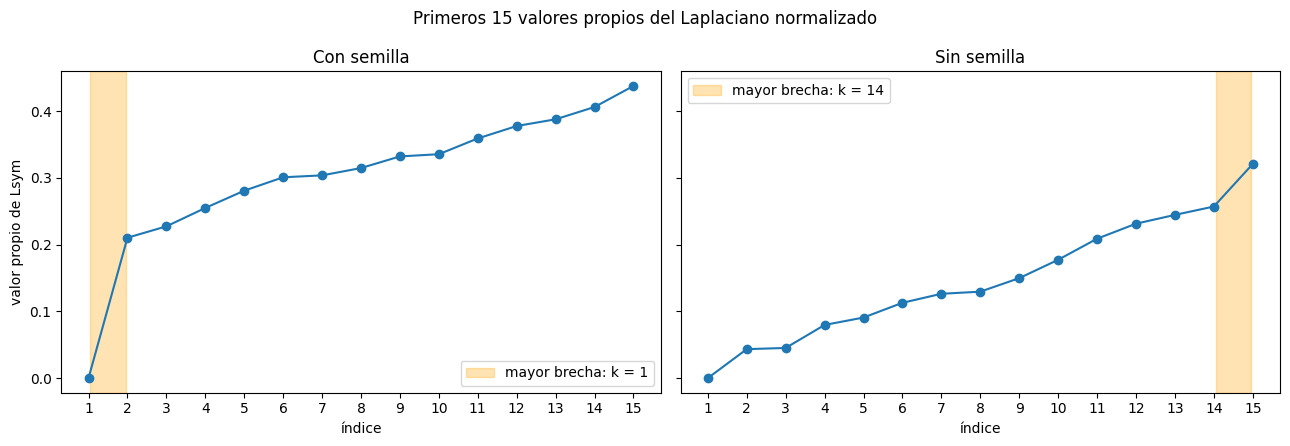


k por la mayor brecha: 1 | k usado para el clustering: 14


In [9]:
_, Lsym_sin, _ = laplacianos(A_sin)
val_con, vec_con = np.linalg.eigh(Lsym_con)   
val_sin, vec_sin = np.linalg.eigh(Lsym_sin)

print(f"λ2 con semilla: {val_con[1]:.6f}")
print(f"λ2 sin semilla: {val_sin[1]:.6f}")

def brechas(valores, m=15):
    v = valores[:m]
    return v, np.diff(v)        # saltos[k-1] = λ_{k+1} - λ_k

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (etiqueta, vals) in zip(axes, [("Con semilla", val_con), ("Sin semilla", val_sin)]):
    v, saltos = brechas(vals)
    k = int(np.argmax(saltos)) + 1
    ax.plot(range(1, len(v) + 1), v, "o-")
    ax.axvspan(k + 0.05, k + 0.95, color="orange", alpha=0.3, label=f"mayor brecha: k = {k}")
    ax.set_title(etiqueta)
    ax.set_xlabel("índice")
    ax.set_xticks(range(1, len(v) + 1))
    ax.legend()
    print(f"\n{etiqueta}: mayor brecha entre λ{k} y λ{k+1} = {saltos[k-1]:.4f}  ->  k = {k}")
    for i, s in enumerate(saltos, start=1):
        print(f"  λ{i+1} - λ{i} = {s:.4f}")
axes[0].set_ylabel("valor propio de Lsym")
plt.suptitle("Primeros 15 valores propios del Laplaciano normalizado")
plt.tight_layout()
plt.savefig("figuras/espectro_lsym.png", dpi=200, bbox_inches="tight")
plt.show()

# k para el clustering espectral (con la semilla)
_, saltos_con = brechas(val_con)
k_brecha = int(np.argmax(saltos_con)) + 1
k_clusters = k_brecha if k_brecha >= 2 else int(np.argmax(saltos_con[1:])) + 2
print(f"\nk por la mayor brecha: {k_brecha} | k usado para el clustering: {k_clusters}")

**Respuesta (b).** La conectividad algebraica, representada por λ₂, fue de 0.210369 con Daniel Radcliffe y de 0.043405 al eliminarlo. Esta disminución indica que, aunque el grafo continúa conectado, sus conexiones internas se vuelven más débiles al retirar al actor principal.

Al analizar los primeros 15 valores propios, la mayor brecha con la semilla apareció entre λ₁ y λ₂, con una diferencia de 0.2104, lo que sugiere k = 1. Este resultado describe una red globalmente conectada, pero no permite dividirla en varias comunidades. Por ello, para el clustering se utilizó la mayor brecha considerando k ≥ 2, que corresponde a k = 14. En el grafo sin la semilla también se encontró la mayor brecha entre λ₁₄ y λ₁₅, con una diferencia de 0.0638.

Esto demuestra que un grafo puede ser conexo y, al mismo tiempo, presentar comunidades internas. La presencia de Daniel Radcliffe fortalece la conexión global, pero no elimina los grupos de actores que colaboran con mayor frecuencia entre sí.

### (c) Clustering espectral

Se toman los $k$ vectores propios de $L_{sym}$ con los valores propios más pequeños, se normaliza cada fila a norma 1 y se aplica k-means (Ng, Jordan y Weiss).


Comunidad 0 (11 actores)
  Mayor grado: Toni Collette (10), Alan Cumming (9), Michael C. Hall (7)
  Películas más repetidas:
    Kill Your Darlings (2013) — 4 integrantes
    Imperium (2016) — 4 integrantes
    Endgame & Rough for Theatre II (2020) — 3 integrantes

Comunidad 1 (4 actores)
  Mayor grado: Alex Russell (6), Thomas Kretschmann (5), Joel Jackson (4)
  Películas más repetidas:
    Jungle (2017) — 4 integrantes
    Wasted on the Young (2010) — 1 integrantes
    Chronicle (2012) — 1 integrantes

Comunidad 2 (10 actores)
  Mayor grado: Ciarán Hinds (12), Paul Dano (9), Zoe Kazan (8)
  Películas más repetidas:
    What If (2014) — 4 integrantes
    Swiss Army Man (2016) — 4 integrantes
    There Will Be Blood (2007) — 2 integrantes

Comunidad 3 (20 actores)
  Mayor grado: Daniel Radcliffe (100), Rupert Grint (16), Ralph Fiennes (15)
  Películas más repetidas:
    Harry Potter and the Chamber of Secrets (2002) — 5 integrantes
    Harry Potter and the Goblet of Fire (2005) — 5 in

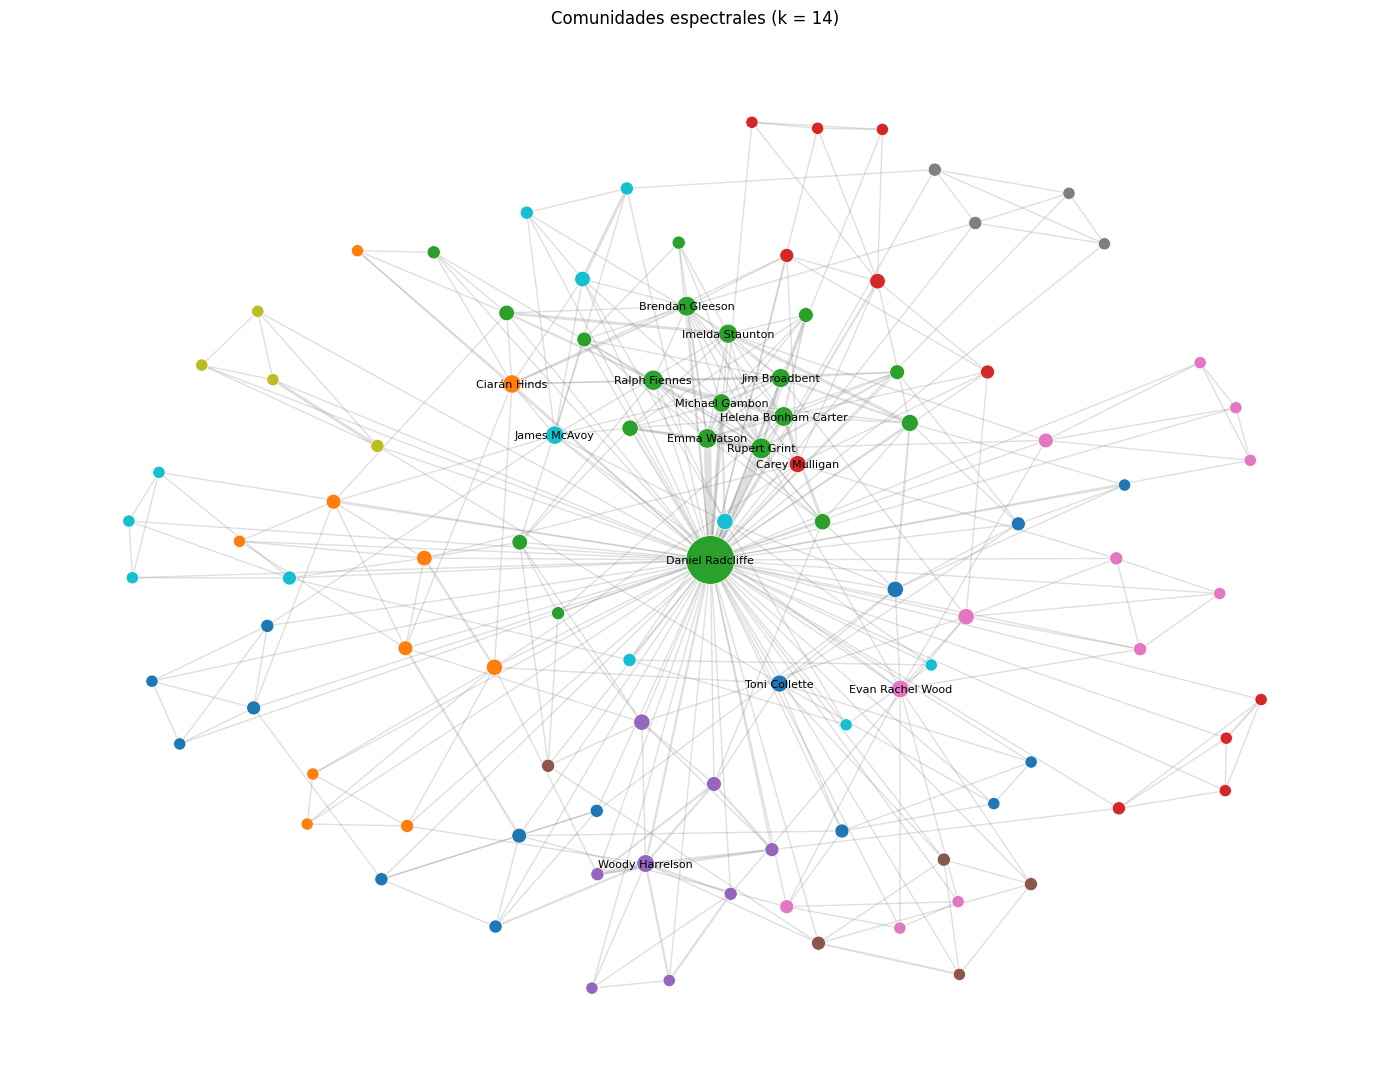

In [10]:
from collections import Counter
from sklearn.cluster import KMeans

U = vec_con[:, :k_clusters]                                   # k vectores propios de los λ más pequeños
U_norm = U / np.linalg.norm(U, axis=1, keepdims=True)         # cada fila a norma 1 (Ng–Jordan–Weiss)
etiquetas = KMeans(n_clusters=k_clusters, n_init=50, random_state=0).fit_predict(U_norm)

titulos = {}
for pelis in pelis_por_actor.values():
    for id_peli, c in pelis.items():
        titulos[id_peli] = f'{c["title"]} ({c["release_date"][:4]})'

for c in range(k_clusters):
    miembros = np.flatnonzero(etiquetas == c)
    top_grado = sorted(miembros, key=lambda i: -grado[ids[i]])[:3]
    conteo = Counter(id_peli for i in miembros for id_peli in pelis_por_actor[ids[i]])
    print(f"\nComunidad {c} ({len(miembros)} actores)")
    print("  Mayor grado:", ", ".join(f"{nombres[i]} ({grado[ids[i]]})" for i in top_grado))
    print("  Películas más repetidas:")
    for id_peli, veces in conteo.most_common(3):
        print(f"    {titulos[id_peli]} — {veces} integrantes")

dibujar_grafo(A, nombres, colores=etiquetas, titulo=f"Comunidades espectrales (k = {k_clusters})",
              archivo="figuras/grafo_comunidades.png")

**Respuesta (c).** El clustering espectral permitió identificar 14 comunidades de actores. Estas agrupaciones presentan relaciones con producciones cinematográficas y teatrales concretas, lo que demuestra que la estructura del grafo refleja colaboraciones reales.

La comunidad más grande contiene 20 actores, entre ellos Daniel Radcliffe, Rupert Grint y Ralph Fiennes, y está relacionada principalmente con la franquicia Harry Potter. También se identificaron grupos asociados con películas como Jungle, Guns Akimbo, Swiss Army Man y Now You See Me, cuyos integrantes comparten participaciones en las mismas producciones.

Otras comunidades están relacionadas con obras teatrales filmadas, como Merrily We Roll Along y Rosencrantz & Guildenstern Are Dead. Esto se debe a que TMDB también incluye determinados especiales y producciones teatrales registradas como películas.

En general, las comunidades reflejan principalmente colaboraciones en películas o franquicias específicas, aunque no necesariamente representan una separación por país o década.

### (d) Vector de Fiedler

Corte de la componente más grande del grafo sin la semilla según el signo del vector propio de $\lambda_2$ de $L_{sym}$.

In [11]:
comps_sin = componentes_bfs(A_sin)
grande = np.array(sorted(max(comps_sin, key=len)))
A_g = A_sin[np.ix_(grande, grande)]
nombres_g = [nombres_sin[i] for i in grande]
ids_g = [ids_sin[i] for i in grande]

_, Lsym_g, _ = laplacianos(A_g)
val_g, vec_g = np.linalg.eigh(Lsym_g)
fiedler = vec_g[:, 1]                    # vector propio de λ2
lado = fiedler >= 0

print(f"Componente más grande sin la semilla: {len(grande)} de {len(A_sin)} actores | λ2 = {val_g[1]:.6f}")
cruzan = A_g[np.ix_(lado, ~lado)]
print(f"Aristas que cruzan el corte: {int((cruzan > 0).sum())} (peso total {int(cruzan.sum())})")
print(f"Aristas dentro de cada lado: {int(np.triu(A_g[np.ix_(lado, lado)] > 0).sum())} "
      f"y {int(np.triu(A_g[np.ix_(~lado, ~lado)] > 0).sum())}")

for nombre_lado, mascara in [("Lado +", lado), ("Lado −", ~lado)]:
    miembros = np.flatnonzero(mascara)
    conteo = Counter(id_peli for i in miembros for id_peli in pelis_por_actor[ids_g[i]])
    print(f"\n{nombre_lado} ({len(miembros)} actores):")
    print("  ", ", ".join(nombres_g[i] for i in miembros[np.argsort(-np.abs(fiedler[miembros]))][:10]))
    print("  Películas más repetidas:", "; ".join(f"{titulos[p]} ({v})" for p, v in conteo.most_common(3)))

Componente más grande sin la semilla: 100 de 100 actores | λ2 = 0.043405
Aristas que cruzan el corte: 20 (peso total 22)
Aristas dentro de cada lado: 65 y 188

Lado + (34 actores):
   Rhys Darby, Samara Weaving, Ned Dennehy, Natasha Liu Bordizzo, James Fraser, Christian Byers, Jack Thompson, Lee Cormie, Dave Franco, Woody Harrelson
  Películas más repetidas: December Boys (2007) (4); Kill Your Darlings (2013) (4); Now You See Me (2013) (4)

Lado − (66 actores):
   Rupert Grint, Emma Watson, Michael Gambon, Helena Bonham Carter, Imelda Staunton, Ralph Fiennes, Brendan Gleeson, Jim Broadbent, Andrew Scott, Joe Dempsie
  Películas más repetidas: Harry Potter and the Philosopher's Stone (2001) (4); Harry Potter and the Chamber of Secrets (2002) (4); Harry Potter and the Prisoner of Azkaban (2004) (4)


**Respuesta (d).** Al eliminar a Daniel Radcliffe, la componente más grande conserva los 100 actores restantes. El vector de Fiedler permitió dividirlos en dos grupos de 34 y 66 actores, respectivamente.

El primer grupo contiene actores relacionados con producciones como December Boys, Kill Your Darlings y Now You See Me. El segundo concentra a varios integrantes de la franquicia Harry Potter, entre ellos Rupert Grint, Emma Watson, Michael Gambon y Ralph Fiennes.

Entre ambos grupos únicamente cruzan 20 aristas, con un peso total de 22, mientras que dentro de los grupos existen 65 y 188 aristas, respectivamente. Esto indica que las conexiones internas son considerablemente más numerosas que las conexiones entre los dos grupos.

Por lo tanto, el corte de Fiedler permite identificar una separación estructural entre el núcleo asociado con Harry Potter y una parte importante de las colaboraciones de Radcliffe en otras producciones, aunque ambos grupos continúan conectados.

### (e) Centralidad

In [12]:
val_A, vec_A = np.linalg.eigh(A)
j = np.argmax(np.abs(val_A))                 # valor propio más grande en valor absoluto
centralidad = np.abs(vec_A[:, j])            # el signo de un vector propio es arbitrario
centralidad = centralidad / centralidad.max()

top_grado = sorted(range(len(ids)), key=lambda i: -grado[ids[i]])[:5]
top_cent = np.argsort(-centralidad)[:5]

print(f"Valor propio dominante de A: {val_A[j]:.4f}\n")
print(f"{'Top 5 por grado':<40}{'Top 5 por centralidad de vector propio'}")
for a, b in zip(top_grado, top_cent):
    print(f"{nombres[a] + f' ({grado[ids[a]]})':<40}{nombres[b]} ({centralidad[b]:.3f})")

cent_nx = nx.eigenvector_centrality_numpy(nx.from_numpy_array(A), weight="weight")
cent_nx = np.array([cent_nx[i] for i in range(len(ids))])
cent_nx /= cent_nx.max()
print("\nCoincide con networkx:", np.allclose(centralidad, cent_nx, atol=1e-6))

Valor propio dominante de A: 23.3869

Top 5 por grado                         Top 5 por centralidad de vector propio
Daniel Radcliffe (100)                  Daniel Radcliffe (1.000)
Rupert Grint (16)                       Rupert Grint (0.836)
Ralph Fiennes (15)                      Emma Watson (0.815)
Emma Watson (14)                        Michael Gambon (0.430)
Brendan Gleeson (14)                    Helena Bonham Carter (0.368)

Coincide con networkx: True


**Respuesta (e).** Los cinco actores con mayor grado fueron Daniel Radcliffe, Rupert Grint, Ralph Fiennes, Emma Watson y Brendan Gleeson. En cambio, los cinco con mayor centralidad de vector propio fueron Daniel Radcliffe, Rupert Grint, Emma Watson, Michael Gambon y Helena Bonham Carter.

Ambas clasificaciones coinciden en tres actores, pero presentan diferencias porque miden características distintas. El grado representa la cantidad de conexiones directas de un actor, mientras que la centralidad de vector propio considera también la importancia de los actores con quienes está conectado.

Por esta razón, Ralph Fiennes y Brendan Gleeson destacan por su número de conexiones, mientras que Michael Gambon y Helena Bonham Carter adquieren mayor importancia al considerar la estructura completa de la red y sus conexiones con otros actores centrales. Daniel Radcliffe ocupa el primer lugar en ambas medidas debido a su posición como actor semilla y su participación en las conexiones principales del grafo.

## I.7 El puente: $A = BB^\top$

$B$ es la matriz de actores por películas, con $B_{am} = 1$ si la película $m$ cuenta para el actor $a$.

In [13]:
pelis = sorted(actores_por_peli)
col = {p: m for m, p in enumerate(pelis)}
B = np.zeros((len(ids), len(pelis)))
for i, id_actor in enumerate(ids):
    for id_peli in pelis_por_actor[id_actor]:
        B[i, col[id_peli]] = 1               # B_am = 1 si la película m cuenta para el actor a

BBt = B @ B.T
fuera = ~np.eye(len(ids), dtype=bool)
print(f"B: {B.shape[0]} actores × {B.shape[1]} películas")
print("B Bᵀ coincide con A fuera de la diagonal:", np.array_equal(BBt[fuera], A[fuera]))

diag = np.diag(BBt)
print("Diagonal = películas que cuentan para cada actor:",
      all(diag[i] == len(pelis_por_actor[ids[i]]) for i in range(len(ids))))
for i in np.argsort(-diag)[:5]:
    print(f"  {nombres[i]:<30} {int(diag[i])} películas")

B: 101 actores × 2426 películas
B Bᵀ coincide con A fuera de la diagonal: True
Diagonal = películas que cuentan para cada actor: True
  Jim Broadbent                  88 películas
  Woody Harrelson                75 películas
  Michael Gambon                 73 películas
  Thomas Kretschmann             72 películas
  Toni Collette                  69 películas


**Respuesta.** Se construyó una matriz B de 101 actores por 2,426 películas, donde cada entrada indica si un actor participó en una película determinada. Al multiplicar B por su transpuesta, se comprobó que los elementos fuera de la diagonal coinciden con los pesos de la matriz de adyacencia A. Esto ocurre porque cada elemento representa la cantidad de películas compartidas entre dos actores.

La diagonal de BBᵀ contiene el número de películas registradas para cada actor, mientras que la diagonal de A es cero porque no se consideran conexiones de un actor consigo mismo. La matriz B incluye 2,426 películas debido a que reúne la filmografía válida de todos los actores incorporados, no solamente las películas de Daniel Radcliffe. Las películas donde aparece un único actor del grafo no generan conexiones adicionales entre actores distintos, por lo que no alteran la coincidencia fuera de la diagonal.

**La analogía con el kernel del bosque.** La matriz BBᵀ funciona de manera similar al kernel de un bosque de árboles de decisión, ya que ambas representan similitudes a partir de características compartidas. En el grafo, dos actores tienen mayor similitud cuando participan en las mismas películas. En un bosque, dos observaciones tienen mayor similitud cuando terminan en las mismas hojas de los árboles. En ambos casos, la matriz resultante permite estudiar qué elementos están relacionados y utilizar herramientas espectrales para identificar grupos con características comunes.